In [97]:
import sys
print(sys.executable)

c:\Users\Antra\projects\assignment1\.venv\Scripts\python.exe


In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [99]:
import sys

assert sys.version_info >= (3, 7)

In [100]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [101]:
def load_acled_data(path):
    return pd.read_csv(path, parse_dates=["event_date"])

acled = load_acled_data("acled.csv")
acled.shape

(169578, 31)

In [102]:
# Check column types and missing values (like Géron's housing.info())
acled.info()

<class 'pandas.DataFrame'>
RangeIndex: 169578 entries, 0 to 169577
Data columns (total 31 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   event_id_cnty       169578 non-null  str           
 1   event_date          169578 non-null  datetime64[us]
 2   year                169578 non-null  int64         
 3   time_precision      169578 non-null  int64         
 4   disorder_type       169578 non-null  str           
 5   event_type          169578 non-null  str           
 6   sub_event_type      169578 non-null  str           
 7   actor1              169578 non-null  str           
 8   assoc_actor_1       32523 non-null   str           
 9   inter1              169578 non-null  str           
 10  actor2              83527 non-null   str           
 11  assoc_actor_2       6736 non-null    str           
 12  inter2              83527 non-null   str           
 13  interaction         169578 non-null  str

In [103]:
print(acled["country"].value_counts())
print()
print(acled["event_type"].value_counts())

country
Ukraine              136165
Russia                33206
Mediterranean Sea       166
Pacific Ocean            24
Atlantic Ocean           15
Arctic Ocean              2
Name: count, dtype: int64

event_type
Explosions/Remote violence    112484
Battles                        44669
Strategic developments         10002
Protests                        1585
Violence against civilians       795
Riots                             43
Name: count, dtype: int64


In [104]:
# Summary statistics of fatalities per event, and the share of events with zero deaths
print(acled["fatalities"].describe())
print("Share of events with 0 fatalities:", (acled["fatalities"] == 0).mean())

count    169578.000000
mean          0.911362
std           5.922991
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         594.000000
Name: fatalities, dtype: float64
Share of events with 0 fatalities: 0.8333097453679132


Dataset & problem definition: The data set I'm using is from Armed Conflict Location & Event Data project(ACLED), they are independent non profit organization that collects data on conflicts through multiple sources such as OSINT and a network of local partners. Fatalities are the total reported deaths per event across all parties both militaries and civilians ACLED does not break them down by side. My dataset is based on the Russia Ukraine conflict and ranges from 1 Aug 2023 – 19 Sep 2025. The dataset has 169,578 events and 31 columns. Weekly fatalities range from 0 to over 1,000 per region, so they are treated as a continuous target, which makes this a regression problem.

My main focus will be on the Ukrainian incursion into Kursk because I want to see if a model can forecast deaths on a front that opened suddenly as well as fronts like Donetsk and Kherson. In the raw data one row is one conflict event such as the Russian armed forces shelling Bakhmut, for the regression task I will aggregate the data to where each new row then summarizes a whole week on one front because around 83% of events have zero fatalities, the median is 0, and the max is 594. For example Kursk week of 12 August 2024. That row holds the total events, battles, explosions and fatalities that week, the fatalities in previous weeks, and the target that I am trying to predict is next week's total fatalities in each frontline region, from that region's activity this week and in recent weeks.

Essentially I think the model is useful as a short term forecast of expected fatalities on active fronts, which could support planning of medical and reinforcements tasks. The Kursk comparison also tests its main limitation a model built on past activity may not anticipate a sudden offensive on a previously quiet front.





In [105]:
# Keep only events in the 11 frontline oblasts (this also drops events coded to seas/oceans)
UKR_FRONT = ["Donetsk", "Kherson", "Kharkiv", "Zaporizhia", "Luhansk", "Sumy", "Dnipropetrovsk", "Chernihiv"]
RUS_FRONT = ["Kursk", "Belgorod", "Bryansk"]
FRONT = UKR_FRONT + RUS_FRONT

events = acled[acled["admin1"].isin(FRONT)].copy()
print("Events kept:", len(events), "of", len(acled))
print("Share of all fatalities kept:", events["fatalities"].sum() / acled["fatalities"].sum())

Events kept: 158738 of 169578
Share of all fatalities kept: 0.9890259920930202


In [106]:
kursk = events[events["admin1"] == "Kursk"]
kursk_monthly = kursk.groupby(kursk["event_date"].dt.to_period("M")).agg(
    events=("fatalities", "size"),
    fatalities=("fatalities", "sum"),
)
kursk_monthly

,events,fatalities
event_date,,
2023-08,21,1
2023-09,47,3
2023-10,36,0
2023-11,16,0
2023-12,21,1
2024-01,18,1
2024-02,35,0
2024-03,50,75
2024-04,57,6


I will show a map of the frontline of Kursk at the start of the incursion and at the end, this is purely for context and kind of understanding whats going on and seeing the other frontlines and where fighting (events) are happening.

In [107]:
pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [108]:
import urllib.request
base = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
urllib.request.urlretrieve(base + "ne_50m_admin_0_countries.geojson", "countries.geojson")
urllib.request.urlretrieve(base + "ne_10m_admin_1_states_provinces.geojson", "regions.geojson")
print("Borders downloaded")

Borders downloaded


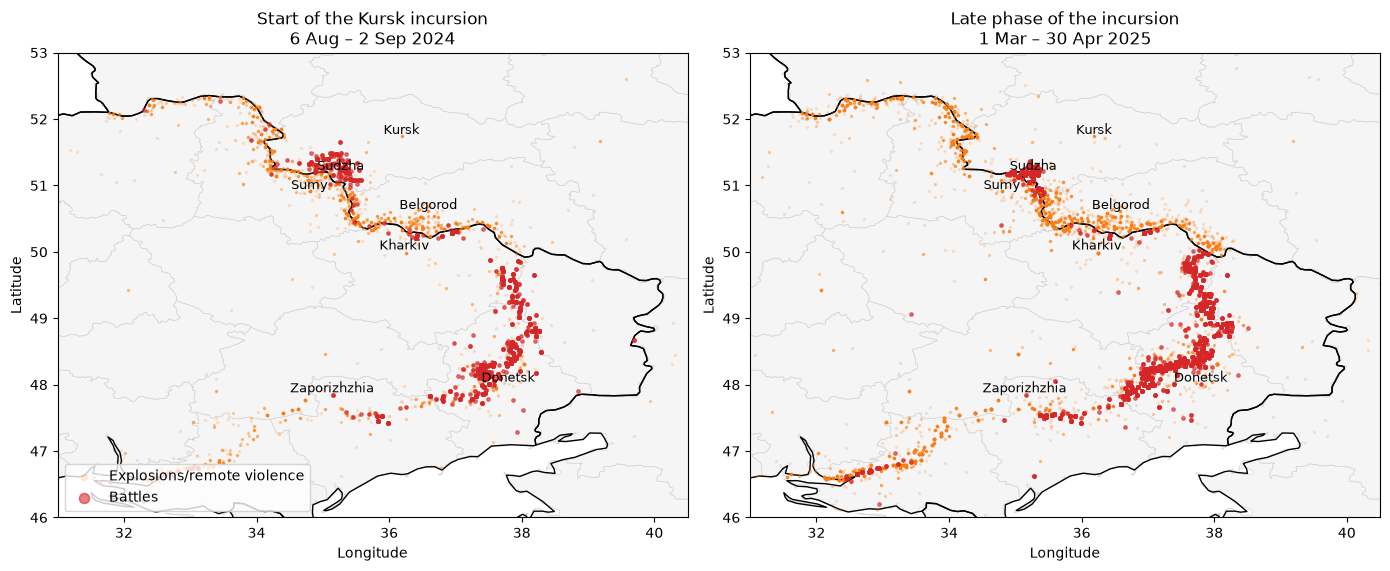

In [109]:
import geopandas as gpd

countries = gpd.read_file("countries.geojson")
regions = gpd.read_file("regions.geojson")
regions = regions[regions["admin"].isin(["Ukraine", "Russia"])]

periods = {"Start of the Kursk incursion\n6 Aug – 2 Sep 2024": ("2024-08-06", "2024-09-02"),
           "Late phase of the incursion\n1 Mar – 30 Apr 2025": ("2025-03-01", "2025-04-30")}

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax, (title, (start, end)) in zip(axs, periods.items()):
    regions.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.5)
    countries.plot(ax=ax, color="none", edgecolor="black", linewidth=1)

    window = acled[acled["event_date"].between(start, end)]
    explosions = window[window["event_type"] == "Explosions/Remote violence"]
    battles = window[window["event_type"] == "Battles"]
    ax.scatter(explosions["longitude"], explosions["latitude"], s=2, color="tab:orange", alpha=0.15, label="Explosions/remote violence")
    ax.scatter(battles["longitude"], battles["latitude"], s=6, color="tab:red", alpha=0.6, label="Battles")

    for name, lon, lat in [("Kursk", 36.19, 51.73), ("Sudzha", 35.27, 51.19), ("Sumy", 34.80, 50.90),
                           ("Belgorod", 36.59, 50.60), ("Kharkiv", 36.23, 49.99),
                           ("Donetsk", 37.80, 48.00), ("Zaporizhzhia", 35.14, 47.84)]:
        ax.text(lon, lat, name, fontsize=9, ha="center", va="bottom")

    ax.set_xlim(31, 40.5)
    ax.set_ylim(46, 53)
    ax.set(title=title, xlabel="Longitude", ylabel="Latitude")

axs[0].legend(loc="lower left", markerscale=3)
plt.tight_layout()
plt.show()

In [110]:
# Recode civilian_targeting: ACLED leaves it blank when civilians were NOT targeted, so blank -> 0, filled -> 1
print(events["civilian_targeting"].value_counts(dropna=False))
events["civ_targeting"] = events["civilian_targeting"].notna().astype(int)
events["civ_targeting"].value_counts()

civilian_targeting
NaN                   148267
Civilian targeting     10471
Name: count, dtype: int64


civ_targeting
0    148267
1     10471
Name: count, dtype: int64

In [111]:
events.nlargest(8, "fatalities")[["event_date", "admin1", "event_type", "sub_event_type", "fatalities"]]

,event_date,admin1,event_type,sub_event_type,fatalities
19256,2023-11-15,Zaporizhia,Battles,Armed clash,594
14858,2023-10-19,Donetsk,Battles,Armed clash,450
50966,2024-05-20,Donetsk,Battles,Armed clash,400
14502,2023-10-18,Zaporizhia,Battles,Armed clash,322
50829,2024-05-20,Kharkiv,Battles,Armed clash,263
87812,2024-11-11,Kherson,Battles,Armed clash,230
39889,2024-03-18,Kherson,Battles,Armed clash,228
53913,2024-06-05,Donetsk,Battles,Armed clash,220


The largest values here are actual mass casulty events, even though they are technically outliers they are real and ACLED uses conservative estimates so the actual numbers would be higher. I'm keeping this data because its important to have because its real. The skew they create is handled instead by applying a log transform to the count features and to the target. A log compresses large values, so a handful of extreme weeks no longer dominates the model's squared error loss.

In [112]:
# Assign each event to the Monday that starts its week, and give event types short column names
events["week"] = events["event_date"].dt.to_period("W-SUN").dt.start_time

type_names = {"Battles": "battles",
              "Explosions/Remote violence": "explosions",
              "Violence against civilians": "vac",
              "Strategic developments": "strategic"}
events["etype"] = events["event_type"].map(type_names).fillna("other")

events[["event_date", "week", "event_type", "etype"]].head()

,event_date,week,event_type,etype
0,2023-08-01,2023-07-31,Explosions/Remote violence,explosions
1,2023-08-01,2023-07-31,Explosions/Remote violence,explosions
2,2023-08-01,2023-07-31,Explosions/Remote violence,explosions
3,2023-08-01,2023-07-31,Explosions/Remote violence,explosions
4,2023-08-01,2023-07-31,Explosions/Remote violence,explosions


In [113]:
# Aggregate to one row per region-week: total fatalities, number of events, civilian-targeting events
weekly = events.groupby(["admin1", "week"]).agg(
    fatalities=("fatalities", "sum"),
    n_events=("fatalities", "size"),
    civ_events=("civ_targeting", "sum"),
)

In [114]:
weekly = weekly.join(pd.crosstab([events["admin1"], events["week"]], events["etype"]))
print("Region-weeks with at least one event:", len(weekly))
weekly.head()

Region-weeks with at least one event: 1230


fatalities  n_events  civ_events  battles  explosions  \
admin1   week                                                                
Belgorod 2023-07-31           0        71           1        0          70   
         2023-08-07           1        51           3        0          41   
         2023-08-14           1        85           1        0          77   
         2023-08-21           4        72           2        0          68   
         2023-08-28           1        58           1        0          43   

                     other  strategic  vac  
admin1   week                               
Belgorod 2023-07-31      0          1    0  
         2023-08-07      0         10    0  
         2023-08-14      0          8    0  
         2023-08-21      0          4    0  
         2023-08-28      0         15    0

In [115]:

all_weeks = pd.date_range(events["week"].min(), events["week"].max(), freq="W-MON")
full_index = pd.MultiIndex.from_product([FRONT, all_weeks], names=["admin1", "week"])
weekly = weekly.reindex(full_index, fill_value=0).reset_index()
print("Rows after filling empty weeks:", len(weekly))

Rows after filling empty weeks: 1232


In [116]:
weekly = weekly[(weekly["week"] > all_weeks.min()) & (weekly["week"] < all_weeks.max())].copy()

In [117]:
# Drop the partial first and last weeks
weekly["country"] = np.where(weekly["admin1"].isin(RUS_FRONT), "Russia", "Ukraine")
print("Rows after dropping partial weeks:", len(weekly))
weekly.head()

Rows after dropping partial weeks: 1210


,admin1,week,fatalities,n_events,civ_events,battles,explosions,other,strategic,vac,country
1,Donetsk,2023-08-07,243,468,32,100,357,0,11,0,Ukraine
2,Donetsk,2023-08-14,173,561,43,75,468,0,18,0,Ukraine
3,Donetsk,2023-08-21,150,500,29,92,392,0,16,0,Ukraine
4,Donetsk,2023-08-28,142,547,39,96,436,0,15,0,Ukraine
5,Donetsk,2023-09-04,180,508,36,98,400,0,10,0,Ukraine


In [118]:
weekly = weekly.sort_values(["admin1", "week"]).reset_index(drop=True)
by_region = weekly.groupby("admin1")

weekly["fat_lag1"] = by_region["fatalities"].shift(1)      # fatalities 1 week ago
weekly["fat_lag2"] = by_region["fatalities"].shift(2)      # 2 weeks ago
weekly["fat_lag4"] = by_region["fatalities"].shift(4)      # 4 weeks ago
weekly["fat_roll4"] = by_region["fatalities"].transform(lambda s: s.rolling(4).mean())
weekly["events_roll4"] = by_region["n_events"].transform(lambda s: s.rolling(4).mean())

In [119]:
weekly["target_next_week_fat"] = by_region["fatalities"].shift(-1)

weekly[weekly["admin1"] == "Kursk"].head(8)[["week", "fatalities", "fat_lag1", "fat_roll4", "target_next_week_fat"]]

,week,fatalities,fat_lag1,fat_roll4,target_next_week_fat
770,2023-08-07,0,NaN,NaN,0.0
771,2023-08-14,0,0.0,NaN,1.0
772,2023-08-21,1,0.0,NaN,0.0
773,2023-08-28,0,1.0,0.25,0.0
774,2023-09-04,0,0.0,0.25,3.0
775,2023-09-11,3,0.0,1.00,0.0
776,2023-09-18,0,3.0,0.75,0.0
777,2023-09-25,0,0.0,0.75,0.0


In [120]:
print(weekly[["fat_lag4", "fat_roll4", "target_next_week_fat"]].isna().sum())

data = weekly.dropna().reset_index(drop=True)
print("\nModelling rows:", len(data))
print("Period:", data["week"].min().date(), "to", data["week"].max().date())
print("Remaining missing values:", data.isna().sum().sum())

fat_lag4                44
fat_roll4               33
target_next_week_fat    11
dtype: int64

Modelling rows: 1155
Period: 2023-09-04 to 2025-09-01
Remaining missing values: 0


These NaNs are dropped because there is no week before a region's first week, so filling them with a median would be creating fatalities and battles that didnt happen. The loss is small, about 5% of rows, and it only affects the first four weeks and the last week of each region.

In [121]:
weeks_sorted = np.sort(data["week"].unique())
cutoff = weeks_sorted[int(len(weeks_sorted) * 0.8)]

train_set = data[data["week"] < cutoff].sort_values(["week", "admin1"]).reset_index(drop=True)
test_set = data[data["week"] >= cutoff].sort_values(["week", "admin1"]).reset_index(drop=True)

print("Train:", len(train_set), "rows,", train_set["week"].min().date(), "to", train_set["week"].max().date())
print("Test: ", len(test_set), "rows,", test_set["week"].min().date(), "to", test_set["week"].max().date())

Train: 924 rows, 2023-09-04 to 2025-04-07
Test:  231 rows, 2025-04-14 to 2025-09-01


Here I have to do something different than the Agerons notebook on github, I cant use random split because in Agerons data each district is independent of the others. My rows are consecutive weeks, so a random split would not work, neighbouring weeks are very similar, and the target for one week is the fatalities value of the next weeks row. If those weeks ended up in different sets, the model would be trained on information from the
future and its score would look good when in reality if we try to predict dates and fatalities that havent happened yet it would be unreliable.

I have to split my data in chronological order, The earliest 80% of weeks form the training set
924 region weeks, 4 Sep 2023 to 7 Apr 2025 and the most recent 20% form the test set 231 region weeks, 14 Apr to 1 Sep 2025.

The training set for Kursk contains the quiet period and the whole incursion, while the test set has the period when fighting in Kursk was winding down.

In [122]:
explore = train_set.copy()
explore["target_next_week_fat"].describe().round(1)

count     924.0
mean      127.4
std       250.2
min         0.0
25%         1.0
50%        14.0
75%       100.5
max      1400.0
Name: target_next_week_fat, dtype: float64

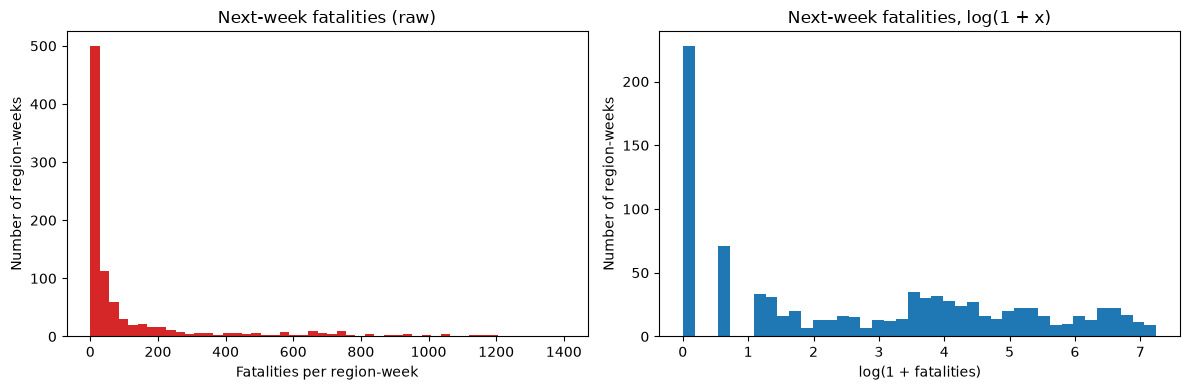

In [123]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].hist(explore["target_next_week_fat"], bins=50, color="tab:red")
axs[0].set(title="Next-week fatalities (raw)",
           xlabel="Fatalities per region-week", ylabel="Number of region-weeks")

axs[1].hist(np.log1p(explore["target_next_week_fat"]), bins=40, color="tab:blue")
axs[1].set(title="Next-week fatalities, log(1 + x)",
           xlabel="log(1 + fatalities)", ylabel="Number of region-weeks")

plt.tight_layout()
plt.show()

In the graphs we can see that most region weeks have around 30 deaths a week, this is combined for both Ukrianian and Russian losses, once again these numbers are very conservative estimates as ACLEDs data tries to be as nuetral as possible, taking numbers from the defence ministries of either country will immensly skew the data as each side under reports losses and inflates gains. That being said, there are a couple regions and a couple of weeks where the fighting was very intense and even with extremely conservative estimates fatalities sit around 1400.

After taking log(1 + x), the values are much more evenly spread, so the few very deadly weeks no longer stand out so much. About a quarter of region weeks still have zero deaths. These are mostly the quiet regions and Kursk before August 2024.

This is why I log transform the target and the count features. I use log(1 + x) instead of
log(x) because log(0) cannot be calculated, and many weeks have zero deaths.

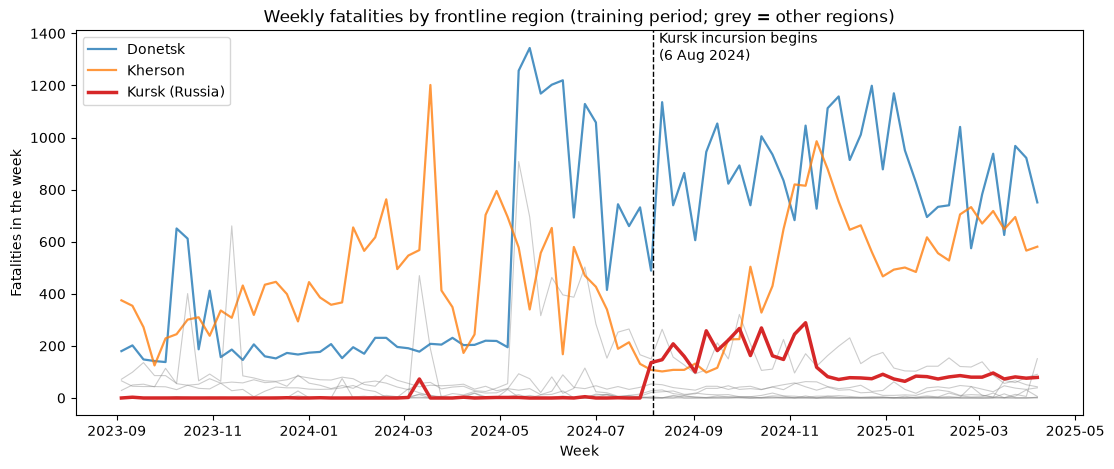

In [124]:
fig, ax = plt.subplots(figsize=(13, 5))

for region, grp in explore.groupby("admin1"):
    if region == "Kursk":
        ax.plot(grp["week"], grp["fatalities"], color="tab:red", lw=2.5, label="Kursk (Russia)", zorder=3)
    elif region in ["Donetsk", "Kherson"]:
        ax.plot(grp["week"], grp["fatalities"], lw=1.6, alpha=0.8, label=region)
    else:
        ax.plot(grp["week"], grp["fatalities"], color="grey", lw=0.8, alpha=0.4)

ax.axvline(pd.Timestamp("2024-08-06"), color="black", ls="--", lw=1)
ax.text(pd.Timestamp("2024-08-10"), ax.get_ylim()[1] * 0.92, "Kursk incursion begins\n(6 Aug 2024)", fontsize=10)

ax.set(title="Weekly fatalities by frontline region (training period; grey = other regions)",
       xlabel="Week", ylabel="Fatalities in the week")
ax.legend(loc="upper left")
plt.show()

Donetsk has been the deadliest front throughout the dataset, with Kherson coming in second. Donetsk also has a spike in fatalities from about 200 deaths a week to over 1,000 in May 2024. Kursk sat at 0 due to the incursion not starting until 6 August 2024, it jumps straight to more than 100 deaths a week, peaks at about 290 in November 2024, and then falls to a steady 90 a week until April 2025.

The sudden jump in Kursk is something no lag feature can see in advance before 6 August, all of Kursk's past weeks look like a quiet front. I therefore expect the model's biggest errors on Kursk to happen right at the start of the incursion because it was a surprise front. I believe that all models in reality will have this problem as wars are complicated and never can be predicted. The Kursk incursion was planned and executed in secret as many military operations are, no model can predict a surprise front.

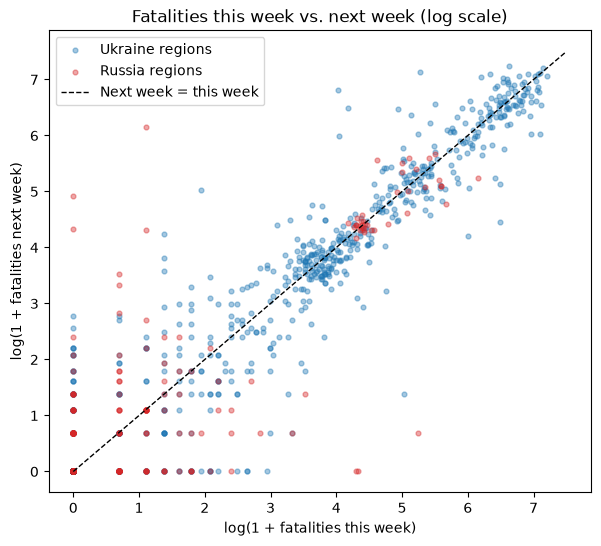

In [125]:
fig, ax = plt.subplots(figsize=(7, 6))
for country, color in [("Ukraine", "tab:blue"), ("Russia", "tab:red")]:
    sub = explore[explore["country"] == country]
    ax.scatter(np.log1p(sub["fatalities"]), np.log1p(sub["target_next_week_fat"]),
               s=12, alpha=0.4, color=color, label=f"{country} regions")

ax.plot([0, 7.5], [0, 7.5], color="black", ls="--", lw=1, label="Next week = this week")
ax.set(title="Fatalities this week vs. next week (log scale)",
       xlabel="log(1 + fatalities this week)", ylabel="log(1 + fatalities next week)")
ax.legend()
plt.show()

The fact the the points are close to the dashed line show that a regions fatalities this week are a strong guide to its fatalities next week. This makes sense as fighting ever rarely stops completely even after a surrender or retreat but rather tends to slow down. This is the reason for using lag and rolling average features. The relationship is tightest on the active fronts and much noisier for quiet regions, where a few deaths more or less make a big relative difference.

The points furthest from the line are sudden changes. The most important for this project is the Ukrainian incursion into Kursk at the far left with high next week values and weeks with zero deaths followed by more than 100. The model can't prdeict these because its features only look at past weeks.

In [126]:
num_cols = ["fatalities", "n_events", "battles", "explosions", "vac", "strategic", "civ_events",
            "fat_lag1", "fat_lag2", "fat_lag4", "fat_roll4", "events_roll4", "target_next_week_fat"]
explore[num_cols].corr()["target_next_week_fat"].sort_values(ascending=False).round(2)

target_next_week_fat    1.00
fat_roll4               0.91
fatalities              0.90
fat_lag1                0.88
fat_lag2                0.86
fat_lag4                0.82
battles                 0.73
civ_events              0.66
events_roll4            0.61
n_events                0.61
explosions              0.28
vac                     0.21
strategic              -0.07
Name: target_next_week_fat, dtype: float64

In [127]:
num_features = ["fatalities", "n_events", "battles", "explosions", "vac", "strategic", "civ_events",
                "fat_lag1", "fat_lag2", "fat_lag4", "fat_roll4", "events_roll4"]
cat_features = ["admin1"]

X_train = train_set[num_features + cat_features]
y_train = train_set["target_next_week_fat"].copy()
print(X_train.shape, y_train.shape)

(924, 13) (924,)



1)  I used time series windows lagged fatalities and a 4 week rolling average, because a region's recent history is the strongest guide to next week.
2) I also used One hot encoding because the region becomes 11 binary columns, so the model can tell Kursk apart from the other fronts. Ordinal encoding would wrongly imply an order between regions.
3) Scaling which I did not use but tested it on a subset. Random Forest is not affected by the scale of features, because it splits on thresholds one feature at a time.

A log(1 + x) transform is applied to the count features and the target to reduce the skew caused by a few extremely deadly weeks.

Missing values are handled in three ways, depending on what the blank means, I recoded civilian_targeting, where blank means they did not target civilians (once again this is very hard to truly verify such as alot of the data relating to this field), and regions that had no events were filled with 0. I dropped the first weeks of each region, which have no history for the lag features. Finally I kept outliers which were the mass fatality events and handled with the log transform.

In [128]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
demo = X_train[["fatalities", "battles"]].head(5)
demo_log = pd.DataFrame(log_transformer.fit_transform(demo).values, columns=["log_fatalities", "log_battles"])
pd.concat([demo.reset_index(drop=True), demo_log], axis=1).round(2)

,fatalities,battles,log_fatalities,log_battles
0,1,0,0.69,0.00
1,1,1,0.69,0.69
2,0,0,0.00,0.00
3,1,0,0.69,0.00
4,180,98,5.20,4.60


In [129]:
from sklearn.preprocessing import StandardScaler

scaler_demo = StandardScaler()
scaled = scaler_demo.fit_transform(X_train[["n_events", "fat_roll4"]])
pd.DataFrame(scaled, columns=["n_events_scaled", "fat_roll4_scaled"]).describe().loc[["mean", "std"]].round(2)

,n_events_scaled,fat_roll4_scaled
mean,-0.0,0.0
std,1.0,1.0


Scaling is not used in the final model. A Random Forest splits on one feature at a time using thresholds. So rescaling a feature changes the threshold's value but not which rows end up on each side. Scaling matters for models that compare distances or use gradients, such as linear regression with regularization, k-nearest neighbours or neural networks.

In [130]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
region_1hot = cat_encoder.fit_transform(X_train[["admin1"]])
pd.DataFrame(region_1hot, columns=cat_encoder.get_feature_names_out()).head(3)

,admin1_Belgorod,admin1_Bryansk,admin1_Chernihiv,admin1_Dnipropetrovsk,admin1_Donetsk,admin1_Kharkiv,admin1_Kherson,admin1_Kursk,admin1_Luhansk,admin1_Sumy,admin1_Zaporizhia
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [131]:
from sklearn.compose import ColumnTransformer

preprocessing = ColumnTransformer([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])
X_train_prepared = preprocessing.fit_transform(X_train)
print("Prepared training matrix:", X_train_prepared.shape)
preprocessing.get_feature_names_out()

Prepared training matrix: (924, 23)


array(['log__fatalities', 'log__n_events', 'log__battles',
       'log__explosions', 'log__vac', 'log__strategic', 'log__civ_events',
       'log__fat_lag1', 'log__fat_lag2', 'log__fat_lag4',
       'log__fat_roll4', 'log__events_roll4', 'cat__admin1_Belgorod',
       'cat__admin1_Bryansk', 'cat__admin1_Chernihiv',
       'cat__admin1_Dnipropetrovsk', 'cat__admin1_Donetsk',
       'cat__admin1_Kharkiv', 'cat__admin1_Kherson', 'cat__admin1_Kursk',
       'cat__admin1_Luhansk', 'cat__admin1_Sumy',
       'cat__admin1_Zaporizhia'], dtype=object)

This is Agerons Select and Train a Model

The model I am using is a random forest regressor. It averages many decision trees, captures non linear relationships and combinations, I needed to use this because there are many battles in Donetsk and if you wanted to have a more accurate model you would need to go all the way back to and use data from 2014 when the Donbas conflict started, it also doesn't need feature scaling. The model is trained on log1 + next week fatalities and its predictions are converted back to real fatalities, so all errors are reported in fatalities per region week. If we assume that fatalities will stay the same every week the error will be much larger than using the random forest regressor. 

Say Donetsk had 740 fatalities in the week of 19 August 2024. If we just assume the same as the week previously it would be 740. Random Forest predicts, 839 using battles, history, the region and so on. What actually happened was 864 fatalities.

The baseline was off by 124 and the forest by 25.


In [132]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor

forest_reg = TransformedTargetRegressor(
    regressor=make_pipeline(preprocessing, RandomForestRegressor(random_state=42, n_jobs=-1)),
    func=np.log1p, inverse_func=np.expm1)
forest_reg.fit(X_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['fatalities','n_events','battles',...,'fat_roll4','events_roll4','admin1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,13
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"


Essentially what this cell is doing is setting up and training the model. I gave it the training weeks and the right answers which are next week's deaths, and it built 100 trees that learned patterns from them.

In [133]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

train_pred = forest_reg.predict(X_train)
train_rmse = root_mean_squared_error(y_train, train_pred)
train_mae = mean_absolute_error(y_train, train_pred)
base_train_rmse = root_mean_squared_error(y_train, X_train["fatalities"])
base_train_mae = mean_absolute_error(y_train, X_train["fatalities"])

print(f"Random Forest  - train RMSE: {train_rmse:6.1f}   train MAE: {train_mae:5.1f}")
print(f"Naive baseline - train RMSE: {base_train_rmse:6.1f}   train MAE: {base_train_mae:5.1f}")

Random Forest  - train RMSE:   52.0   train MAE:  16.4
Naive baseline - train RMSE:  108.8   train MAE:  40.0


This cell checked how well it did on those same weeks. It obviously did very well but that doesnt mean the model is actually any good at predicting since it had the answers. The real test is how the model does on weeks it hasn't seen, which is what cross validation measures.

In [134]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)
forest_rmses = -cross_val_score(forest_reg, X_train, y_train,
                                scoring="neg_root_mean_squared_error", cv=tscv)
fold_info = [(train_set.loc[val_idx, "week"].min().date(), train_set.loc[val_idx, "week"].max().date())
             for _, val_idx in tscv.split(X_train)]
pd.DataFrame({"validation_weeks": [f"{a} to {b}" for a, b in fold_info], "RMSE": forest_rmses.round(1)})

,validation_weeks,RMSE
0,2023-12-11 to 2024-03-11,108.9
1,2024-03-18 to 2024-06-17,210.5
2,2024-06-24 to 2024-09-23,110.0
3,2024-09-30 to 2024-12-30,120.9
4,2025-01-06 to 2025-04-07,82.8


In [135]:
pd.Series(forest_rmses).describe().round(1)

count      5.0
mean     126.6
std       48.9
min       82.8
25%      108.9
50%      110.0
75%      120.9
max      210.5
dtype: float64

To see if the model is any good we need to check it does on weeks it hasn't seen, I use cross validation. Géron splits the data randomly for this, my rows have to be order so I use time series split instead.

It cuts the training weeks into 5 blocks. Each time, the model trains on the earlier weeks and is tested on the block that comes right after.

On new weeks, the model's average error (RMSE) is about 127 deaths. On the weeks it trained on, it was only 52. So the model does much worse on data it hasn't seen, which means it is overfitting.

The error changes a lot from block to block, from 83 to 211. The model does well when the fighting is steady and badly when a front suddenly changes. The worst block (March to June 2024) is when deaths in Donetsk jumped from about 200 to over 1,000 a week. The model had never seen Donetsk that deadly, and a Random Forest can't predict numbers higher than what it saw in training.

The block with the start of the Kursk incursion June to September 2024 has a lower error of "110". That doesn't mean Kursk was easy to predict. RMSE counts errors in deaths, so the big fronts like Donetsk, with hundreds of deaths a week, affect it much more than Kursk does. I will take a  look at Kursk on its own at the end.

In [136]:
X_test = test_set[num_features + cat_features]
y_test = test_set["target_next_week_fat"].copy()

test_pred = forest_reg.predict(X_test)
test_rmse = root_mean_squared_error(y_test, test_pred)
test_mae = mean_absolute_error(y_test, test_pred)
base_test_rmse = root_mean_squared_error(y_test, X_test["fatalities"])
base_test_mae = mean_absolute_error(y_test, X_test["fatalities"])

results = pd.DataFrame({
    "RMSE": [train_rmse, forest_rmses.mean(), test_rmse, base_test_rmse],
    "MAE": [train_mae, np.nan, test_mae, base_test_mae],
}, index=["Random Forest - train", "Random Forest - cross-validation (mean)",
          "Random Forest - test", "Naive baseline - test"])
results.round(1)

,RMSE,MAE
Random Forest - train,52.0,16.4
Random Forest - cross-validation (mean),126.6,NaN
Random Forest - test,72.1,30.3
Naive baseline - test,85.5,32.3


The model's error on the test weeks (RMSE 72.1, MAE 30.3) is clearly higher than on the
training weeks (RMSE 52.0, MAE 16.4), it partly memorized the training data instead of only learning the general pattern.

It is not underfitting, because it still beats the naive baseline on the test set (RMSE 72.1 vs 85.5, about 16% lower). The gain on MAE is smaller (30.3 vs 32.3), so on a typical week the model is only a little better than copying this week's deaths forward. Most of its
advantage comes from reducing the larger errors.

The test error is lower than the cross-validation error (126.6) because the test period, April to September 2025, was steadier it had no sudden jumps like Donetsk in May 2024 or the start of the Kursk incursion. The test score is therefore probably optimistic, and the cross validation results give a more realistic picture of how the model does when a front suddenly changes.

I now want to demostrate why these type of models can be useful in stable and slower fronts that essentially stay the same but when a large armed conflict happens it not the best and I specifically chose Kursk to demonstrate this.

1) Surprise is a massive part of war, if the other side doesnt know what your planning you have the upper hand. Ukraine (I dont want to get political, but they were also urged by western and NATO generals as they needed some gains to justify the funding and arming of the Ukrainian army through western aid) planned the Kursk incursion in secret precisely so Russia wouldn't see it coming. If Russia's own military intelligence missed it, no model built on public event data could spot it either. The information that would predict the event will never be available publicly.

2) Models learn patterns from history and assume they'll continue. War breaks this assumption repeatedly a new offensive, a collapse of a defensive line, or the encirclement of Ukrainian forces in the Velykyi Burluk direction that started on september 10th of this year. Kursk was quiet for a year, so everything the model learned said "quiet", right up to the week it wasn't. The Donetsk jump in May 2024 did the same thing.

3) Casualty figures come from reports during a war, where both sides have reasons to hide their losses and exaggerate the enemy's. ACLED uses cautious estimates, so even the "true" values the model is scored against carry error. Kursk's unusually flat 75–90 deaths a week from December 2024 may partly reflect how deaths were estimated rather than the fighting itself.

4) A model learns from examples, and a war produces only a handful of major offensives. Your data has thousands of region-weeks of ongoing fighting, but only a couple of fronts opening suddenly. There's too little to learn what the lead-up to an offensive looks like.


What these models can actually do is predict continuation, fronts that are active tend to stay active, which is why the model here beats the baseline on steady fronts.




I will now look at Kursk compared to the other fronts to see if my hypothesis that a model can forecast deaths on a front that opened suddenly is true or false. Essentially can a model trained on past conflict activity forecast a front that opened suddenly (Kursk) as well as long running fronts?

In [137]:
from sklearn.base import clone

oos_parts = []
for tr_idx, val_idx in tscv.split(X_train):
    fold_model = clone(forest_reg).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    part = train_set.loc[val_idx, ["admin1", "week", "target_next_week_fat"]].copy()
    part["predicted"] = fold_model.predict(X_train.iloc[val_idx])
    oos_parts.append(part)

test_part = test_set[["admin1", "week", "target_next_week_fat"]].copy()
test_part["predicted"] = test_pred
oos = pd.concat(oos_parts + [test_part], ignore_index=True)
oos["target_week"] = oos["week"] + pd.Timedelta(weeks=1)
print("Out-of-sample predictions:", len(oos), "region-weeks,",
      oos["target_week"].min().date(), "to", oos["target_week"].max().date())

Out-of-sample predictions: 1001 region-weeks, 2023-12-18 to 2025-09-08


To see how the model handled the Kursk incursion, I need forecasts the model made without having seen those weeks. The test set can't be used for this, because it only covers April to September 2025, when Kursk was winding down. Predictions on the training weeks can't be used either, because the model has partly memorized them.

Instead, I reuse the cross validation blocks. In each block, a fresh copy of the model is trained only on earlier weeks and then forecasts the block that follows. Combined with the test set forecasts, this gives an honest forecast for each week from December 2023 to September 2025, showing what the model would have predicted at the time, knowing only the past.

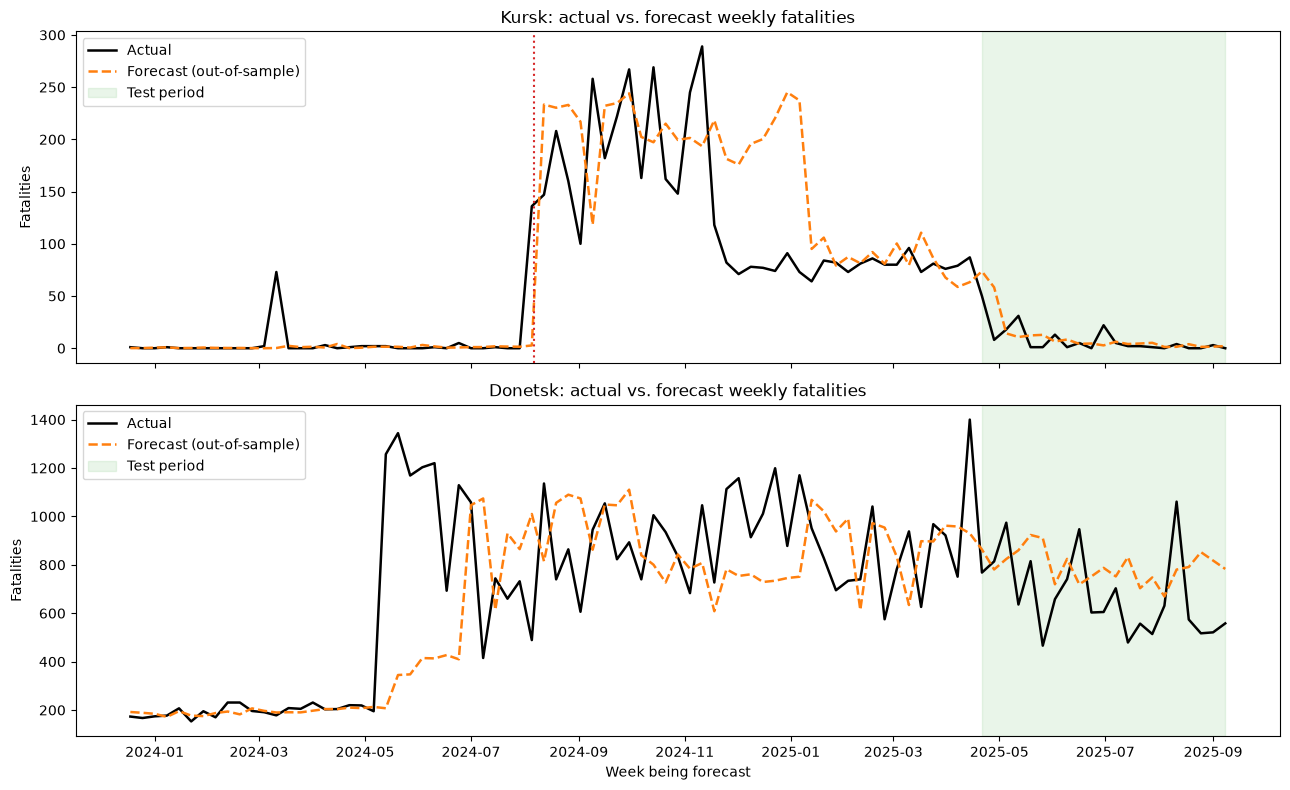

In [138]:
fig, axs = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, region in zip(axs, ["Kursk", "Donetsk"]):
    sub = oos[oos["admin1"] == region]
    ax.plot(sub["target_week"], sub["target_next_week_fat"], color="black", lw=1.8, label="Actual")
    ax.plot(sub["target_week"], sub["predicted"], color="tab:orange", lw=1.8, ls="--", label="Forecast (out-of-sample)")
    ax.axvspan(cutoff + pd.Timedelta(weeks=1), sub["target_week"].max(), color="tab:green", alpha=0.1, label="Test period")
    ax.set(title=f"{region}: actual vs. forecast weekly fatalities", ylabel="Fatalities")
    ax.legend(loc="upper left")
axs[0].axvline(pd.Timestamp("2024-08-06"), color="tab:red", ls=":", lw=1.5)
axs[1].set_xlabel("Week being forecast")
plt.tight_layout()
plt.show()

We can see from the Kursk graph that when the incursion originally began the model forecast almost zero deaths while 136 actual fatalities occurred, because every feature still described a quiet front. It caught up within one week, once the new deaths appeared in the lag features, and then followed Kursk's level fairly well. When we get to November 2024 Kursks actual fatalities drop heavily yet the model still predicts high fatalities for 6 more weeks. This is probably due to Kursk's number of events staying high during this period even though reported deaths fell, so the model still saw a very active front. From January 2025, including the test period, the forecast follows the actual values closely.

Comparing the two fronts Donetsk was a front that was open for a long time. This is also another issue, (this is just for context) the Donetsk front is one that originially opened way back in 2014 and the majority of the fighting was done by Russian backed militias like the Donetsk People's Army (DPR/DNR) and Lugansk People's Army and the Ukrainian armed forces, this is when the infamous battles for the Donetsk airport took place and where certain groups like the Somalia battalion and the cyborg battalion started to formally get integrated into their respective armed forces.

That being said, I just wanted to point out that once again the model cant be extremely accurate as its missing years of data and the years of peace as well, it all circles back that the data needed is also not publicly available.

Moving on to the second graph, Donetsk was a front that was open since the begining of my dataset, is forecast very closely while the fighting is steady. But when its deaths jumped from about 200 to 1,300 a week in May 2024, the model took about seven weeks to catch up, because it had never seen a front that deadly. Kursk
recovered faster because its new level was similar to what the model had already seen on other fronts. Overall, the model is good at following fighting that continues, but it reacts late to sudden changes in either direction.

In [139]:
region_errors = oos.groupby("admin1").apply(lambda g: pd.Series({
    "mean_actual": g["target_next_week_fat"].mean(),
    "MAE": mean_absolute_error(g["target_next_week_fat"], g["predicted"]),
    "RMSE": root_mean_squared_error(g["target_next_week_fat"], g["predicted"]),
}), include_groups=False)
region_errors["MAE_as_%_of_mean"] = 100 * region_errors["MAE"] / region_errors["mean_actual"]
display(region_errors.sort_values("mean_actual", ascending=False).round(1))


,mean_actual,MAE,RMSE,MAE_as_%_of_mean
admin1,,,,
Donetsk,690.2,211.9,310.4,30.7
Kherson,488.7,148.2,209.7,30.3
Kharkiv,139.0,70.2,133.4,50.5
Kursk,55.0,27.7,51.1,50.4
Zaporizhia,48.6,11.1,14.4,22.8
Sumy,23.3,11.7,17.0,50.2
Luhansk,17.3,13.2,25.2,76.4
Dnipropetrovsk,12.8,8.0,14.7,62.2
Belgorod,11.3,13.7,54.6,121.3


In [140]:
kursk_onset = oos[(oos["admin1"] == "Kursk") & oos["target_week"].between("2024-08-05", "2024-09-30")]
kursk_onset[["target_week", "target_next_week_fat", "predicted"]].round({"predicted": 0})

,target_week,target_next_week_fat,predicted
370,2024-08-05,136.0,3.0
381,2024-08-12,147.0,233.0
392,2024-08-19,208.0,230.0
403,2024-08-26,160.0,233.0
414,2024-09-02,100.0,217.0
425,2024-09-09,258.0,118.0
436,2024-09-16,182.0,232.0
447,2024-09-23,222.0,235.0
458,2024-09-30,267.0,244.0


Here I'm looking at error by each region.

The model is most accurate to regions where the fighting is steady and heavy, relative to their average weekly deaths. We can see that for Zaporizhia, Kherson and Donetsk. Kursk's error is around 50% percent, but Kursk is not alone Sumy and Kharkiv also have high error rates for active fronts. Sumy borders Kursk, and Kharkiv
had its own sudden escalation in May 2024. This suggests the difficulty for the model is not Kursk itself, but
any front where the fighting changes quickly.

The very high percentages for the quiet border regions Belgorod, Bryansk and Chernihiv are not meaningful, because they average only a few deaths a week, so even a small miss is a large percentage.

Going back to the start of the Kursk incursion, the first week was way off since the historical data showed that it was a constantly quiet front. the model forecasted 3 deaths while 136 occurred. The next week it overshot 233 forecast vs 147 actual, and from then on it stayed in the right range but was usually one step behind after a quieter week it forecast low 118 on 9 September just as deaths rose again 258.

Once again this proves that the model is essentially a smoothed persistence forecast it assumes the near future looks like the recent past, adjusted by patterns from similar weeks. This is fine for steady fronts but its essentially useless on fronts with sudden changes.

**Final Interpretation of the model and closing remarks**

First I want to look at the train vs test error, here the model overfits. On the weeks it was trained on, the Random Forest's error is 52.0 deaths. On weeks it has not seen, the error is much higher at 126.6 on average in time series cross validation and 72.1 on the test set. A model that does much better on its training data than on new data has partly memorized the training weeks instead of only learning the general pattern.

The model does not underfit, which is good because it would be worse. This current model is still better than the naive keeping the deaths of this week the same as next week. The gain isnt huge though on a typical week it is only a little better than copying this week's deaths forward, because recent history is by far its most useful information.

The test error is lower than the cross validation error. The test period which was April to September 2025 was steady, with no sudden jumps. The cross validation blocks include the sharp rise in Donetsk in May 2024 and the start of the Kursk incursion. A Random Forest cannot predict values beyond what it saw in training, so it does badly right aftersuch jumps. The test score is therefore probably too optimistic, and the cross validation range gives a more realistic picture of the error when a front changes suddenly.

I will quickly mention Kursk one final time as ive already explained whats happened there, essentially the model could not anticipate the incursion, for the first week it forecast 3 deaths while 136 occurred. It caught up the following week, but overshot. From then on it was usually one step behind. It was also slow on the way down, forecasting too many deaths for about six weeks after Kursk's fighting eased in November 2024. We saw this with fronts where sudden changed happened as well, so its a model problem.

Limitation and how to fix them, Overfitting could be reduced by limiting tree size, Predicting the change in deaths rather than the level would help the model with sudden jumps, a random forest cant predict beyond its training range. Possibly taking a look at neighboring regions could help as well to see if activity will increase in a certain region perhaps like a early warning but that is definetly the weakest option. Finally this one is just a dataset issue, we will never have the real numbers, that is all hidden and only the defense ministries know those numbers, if even the numbers they have are accurate.

The model can forecasts ongoing fighting reasonably well but cannot anticipate sudden escalation. This is a limit of forecasting war from past event data, not only of this model, since the decisions that start offensives are
deliberately kept hidden. So to answer to my question "if a model can forecast deaths on a front that opened suddenly?" is definetly no. It can still be used as a guideline short term forecast of expected fatalities on active fronts.

Thank you for looking at my model and I hope you found the topic unique and interesting.
